# DISEASE: DIABETES

### 1. Load

In [2]:
import pandas as pd

df_raw = pd.read_csv("C:/Users/User/Documents/diploma/data/datasets_original/diabetes_binary_health_indicators_BRFSS2015.csv")

print(df_raw.shape)
df_raw.head()

(253680, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [3]:
df_heart = pd.read_csv("C:/Users/User/Documents/diploma/data/datasets_original/heart_disease_health_indicators_BRFSS2015.csv")
comparison = pd.crosstab(
    df_heart["Diabetes"],
    df_raw["Diabetes_binary"]
)

print(comparison)

Diabetes_binary     0.0    1.0
Diabetes                      
0.0              213703      0
1.0                4631      0
2.0                   0  35346


### 2. Rename columns

In [4]:
df = pd.DataFrame(index=df_raw.index)

shared_cols = [
    "HeartDiseaseorAttack",
    "Stroke",
    "Sex",
    "Age",
    "BMI",
    "HighBP",
    "HighChol",
    "CholCheck",
    "Smoker",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "GenHlth",
    "MentHlth",
    "PhysHlth",
    "DiffWalk",
    "Education",
    "Income",
]

for col in shared_cols:
    assert (df_raw[col] == df_heart[col]).all(), (
        f"Row misalignment detected on '{col}'. Do not proceed."
    )
print("All shared columns are row-aligned.")

df["diabetes_severity"] = df_heart["Diabetes"].astype("Int8") 
df["diabetes"] = df_heart["Diabetes"].map({
    0: 0,  
    1: 1, 
    2: 1  
}).astype("Int8")

df["heart_disease"] = df_raw["HeartDiseaseorAttack"].astype("Int8")
df["stroke"] = df_raw["Stroke"].astype("Int8")

df["sex_binary"] = df_raw["Sex"].astype("Int8")
df["sex"] = df_raw["Sex"].map({
    0: "female",
    1: "male"
}).astype("string")

df["age_range"] = df_raw["Age"].astype("Int8")

df["bmi"] = df_raw["BMI"].astype("float")

df["smoker"] = df_raw["Smoker"].astype("Int8")
df["heavy_alcohol"] = df_raw["HvyAlcoholConsump"].astype("Int8")
df["physical_activity"] = df_raw["PhysActivity"].astype("Int8")

df["education"] = df_raw["Education"].astype("Int8")
df["income"] = df_raw["Income"].astype("Int8")

df["high_bp"] = df_raw["HighBP"].astype("Int8")
df["high_chol"] = df_raw["HighChol"].astype("Int8")
df["chol_check"] = df_raw["CholCheck"].astype("Int8")

df["fruits"] = df_raw["Fruits"].astype("Int8")
df["veggies"] = df_raw["Veggies"].astype("Int8")

df["general_health"] = df_raw["GenHlth"].astype("Int8")
df["mental_health"] = df_raw["MentHlth"].astype("Int8")
df["physical_health"] = df_raw["PhysHlth"].astype("Int8")
df["diff_walk"] = df_raw["DiffWalk"].astype("Int8")

df.head()

All shared columns are row-aligned.


,diabetes_severity,diabetes,heart_disease,stroke,sex_binary,sex,age_range,bmi,smoker,heavy_alcohol,...,income,high_bp,high_chol,chol_check,fruits,veggies,general_health,mental_health,physical_health,diff_walk
0,0,0,0,0,0,female,9,40.0,1,0,...,3,1,1,1,0,1,5,18,15,1
1,0,0,0,0,0,female,7,25.0,1,0,...,1,0,0,0,0,0,3,0,0,0
2,0,0,0,0,0,female,9,28.0,0,0,...,8,1,1,1,1,0,5,30,30,1
3,0,0,0,0,0,female,11,27.0,0,0,...,6,1,0,1,1,1,2,0,0,0
4,0,0,0,0,0,female,11,24.0,0,0,...,4,1,1,1,1,1,2,3,0,0


In [6]:
print("Exact duplicates:", df.duplicated().sum())

Exact duplicates: 25199


In [7]:
df["diabetes"].value_counts(normalize=True).mul(100).round(2)

diabetes
0    84.24
1    15.76
Name: proportion, dtype: Float64

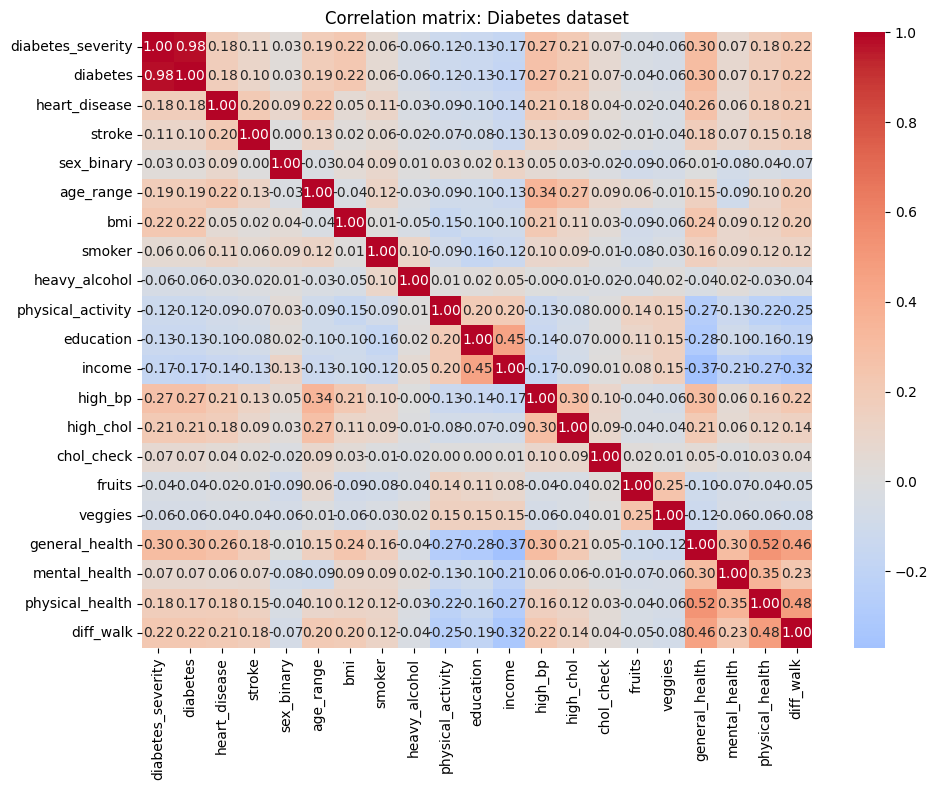

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix: Diabetes dataset")
plt.tight_layout()
plt.show()

In [5]:
target = "diabetes"
corr[target].drop(target).sort_values(key=abs, ascending=False)

diabetes_severity    0.983304
general_health       0.300785
high_bp              0.270334
bmi                  0.223851
diff_walk            0.222155
high_chol            0.210290
age_range            0.185891
heart_disease        0.176933
physical_health      0.174948
income              -0.172794
education           -0.131803
physical_activity   -0.121392
stroke               0.104800
mental_health        0.074971
chol_check           0.067879
smoker               0.062778
veggies             -0.059219
heavy_alcohol       -0.056682
fruits              -0.042088
sex_binary           0.029606
Name: diabetes, dtype: float64

### 3. Save cleaned dataset

In [ ]:
df.to_csv("C:/Users/User/Documents/diploma/data/datasets_cleaned/diabetes_clean.csv", index=False)

print(f"Saved {len(df)} rows × {df.shape[1]} columns")

Saved 253680 rows × 22 columns
